# Mi Red: análisis exploratorio y experimentos

Este notebook estudia el dataset **sintético traducido** usado para clasificar descripciones de red. No inspecciona redes ni demuestra detección de averías físicas. Ejecutar las celdas de arriba hacia abajo.

Fuente: [codingkiddo/smartnet-network-incidents](https://huggingface.co/datasets/codingkiddo/smartnet-network-incidents). La captura de la ficha declara Apache-2.0; falta verificar y conservar su licencia original. El equipo tradujo 12 plantillas con asistencia de IA y conservó cifras y unidades. De 6000 filas quedaron 3146 tras eliminar duplicados normalizados. Los archivos originales se eliminaron a petición del usuario; se conserva la versión preparada.

Las categorías representan señal débil, congestión Wi-Fi, fallo DHCP, latencia alta, riesgo DNS y funcionamiento normal. La última es un estado sin falla, necesario para interpretar el alcance del clasificador.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import re
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
from src.nlp.Normalizacion import normalizar_texto
from src.nlp.Tokenizacion import tokenizar_texto
from src.nlp.Stopwords import obtener_palabras_vacias, eliminar_palabras_vacias

ruta_datos = raiz / "data/raw/incidentes_es.csv"
datos = pd.read_csv(ruta_datos, keep_default_na=False)
metricas = json.loads((raiz / "artifacts/metricas.json").read_text(encoding="utf-8"))
assert hashlib.sha256(ruta_datos.read_bytes()).hexdigest() == metricas["dataset_sha256"], "Las métricas no corresponden a este CSV."
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False})
print(f"Registros: {len(datos)} | Columnas: {list(datos.columns)}")
display(datos.head())

Registros: 3146 | Columnas: ['texto', 'categoria']


,texto,categoria
0,sensor IoT se desconecta repetidamente con una...,SENAL_DEBIL
1,sensor IoT tiene conexión normal con RSSI de -...,FUNCIONAMIENTO_NORMAL
2,Se detectó poca cobertura Wi-Fi para televisor...,SENAL_DEBIL
3,Degradación de la calidad de red para cámara d...,LATENCIA_ALTA
4,televisor inteligente generó actividad DNS inu...,RIESGO_SEGURIDAD_DNS


## 1. Calidad: vacíos y duplicados
Se revisan tanto coincidencias exactas como textos iguales después de aplicar la normalización del programa.

In [2]:
normalizados = datos["texto"].map(normalizar_texto)
calidad = pd.Series({
    "Textos vacíos": datos["texto"].str.strip().eq("").sum(),
    "Categorías vacías": datos["categoria"].str.strip().eq("").sum(),
    "Valores nulos": datos.isna().sum().sum(),
    "Filas duplicadas": datos.duplicated().sum(),
    "Textos duplicados normalizados": normalizados.duplicated().sum(),
})
display(calidad.to_frame("cantidad"))
assert calidad.sum() == 0
print("La ausencia de duplicados exactos NO implica variedad de escenarios o redacción.")

,cantidad
Textos vacíos,0
Categorías vacías,0
Valores nulos,0
Filas duplicadas,0
Textos duplicados normalizados,0


La ausencia de duplicados exactos NO implica variedad de escenarios o redacción.


## 2. Distribución de categorías
El desbalance afecta el aprendizaje y la interpretación de accuracy. F1 macro da la misma importancia a cada categoría.

,cantidad,porcentaje
categoria,,
LATENCIA_ALTA,994,31.60
RIESGO_SEGURIDAD_DNS,857,27.24
FUNCIONAMIENTO_NORMAL,510,16.21
CONGESTION_WIFI,365,11.60
SENAL_DEBIL,308,9.79
FALLO_DHCP,112,3.56


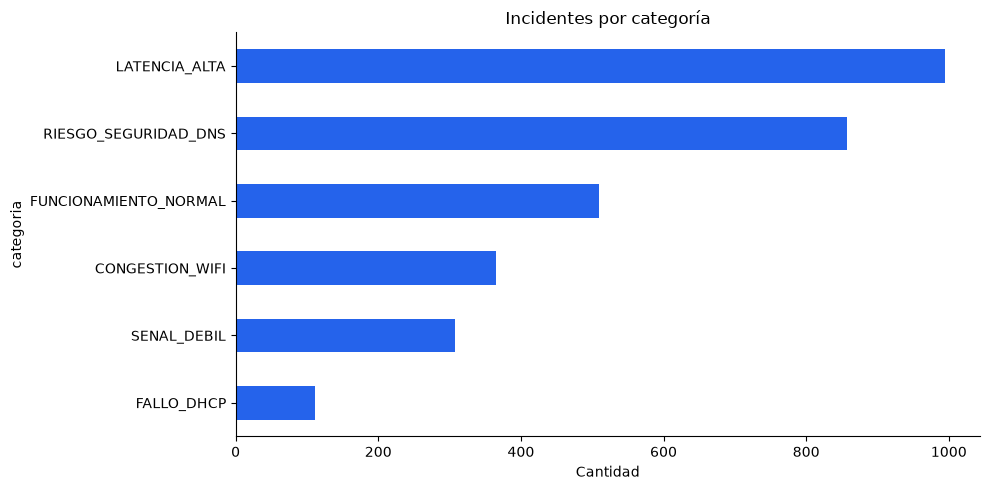

Relación entre clase mayoritaria y minoritaria: 8.88
Regresión logística comparó class_weight=None y balanced. Naive Bayes utilizó sus probabilidades de clase aprendidas. Revisar recall por clase.


In [3]:
distribucion = datos["categoria"].value_counts()
display(pd.DataFrame({"cantidad": distribucion, "porcentaje": (distribucion / len(datos) * 100).round(2)}))
distribucion.sort_values().plot.barh(color="#2563eb", title="Incidentes por categoría", xlabel="Cantidad")
plt.tight_layout()
plt.show()
print(f"Relación entre clase mayoritaria y minoritaria: {distribucion.max() / distribucion.min():.2f}")
print("Regresión logística comparó class_weight=None y balanced. Naive Bayes utilizó sus probabilidades de clase aprendidas. Revisar recall por clase.")

## 3. Longitud de los textos
Los caracteres permiten verificar los límites de la API. Las palabras se cuentan separando por espacios.

,caracteres,palabras
count,3146.00,3146.00
mean,140.29,22.99
std,14.33,3.69
min,94.00,14.00
25%,132.00,20.00
50%,144.00,24.00
75%,151.00,26.00
max,161.00,29.00


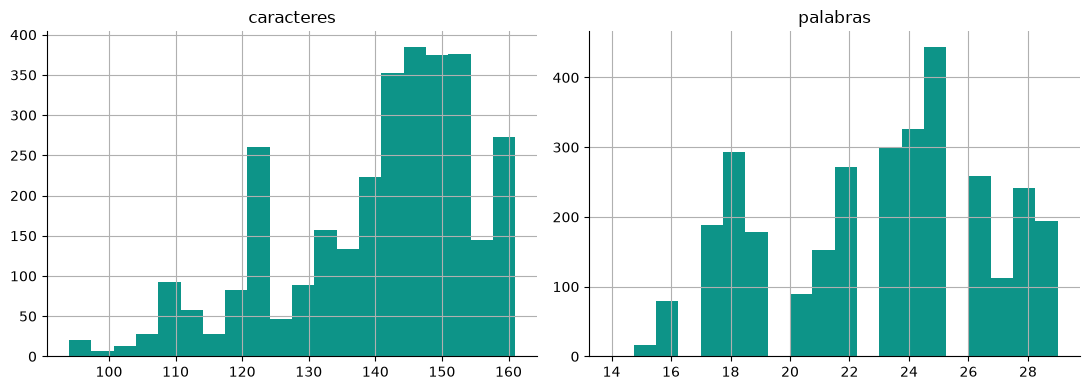

Textos fuera del límite API (10–2000 caracteres): 0


In [4]:
longitudes = pd.DataFrame({"caracteres": datos["texto"].str.len(), "palabras": datos["texto"].str.split().str.len()})
display(longitudes.describe().round(2))
longitudes.hist(bins=20, color="#0d9488", figsize=(11, 4))
plt.tight_layout()
plt.show()
print("Textos fuera del límite API (10–2000 caracteres):", (~longitudes["caracteres"].between(10, 2000)).sum())

## 4. Palabras frecuentes
Se aplica la misma normalización, tokenización y lista de stop words del proyecto. Se conservan negaciones y se excluyen tokens puramente numéricos solo para este gráfico, no para entrenar.

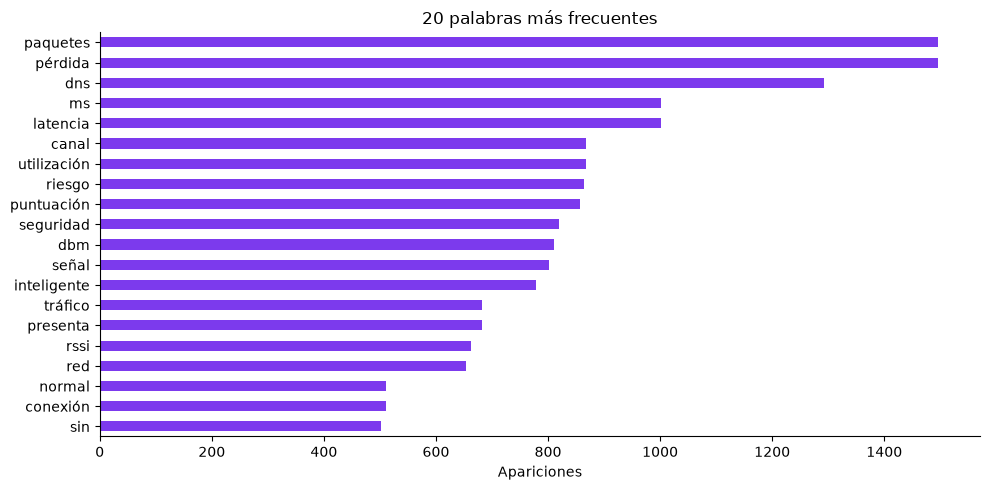

,categoria,palabras_frecuentes
0,CONGESTION_WIFI,"[(utilización, 365), (canal, 365), (probable, ..."
1,FALLO_DHCP,"[(fallos, 112), (dhcp, 112), (no, 104), (obten..."
2,FUNCIONAMIENTO_NORMAL,"[(conexión, 510), (normal, 510), (rssi, 502), ..."
3,LATENCIA_ALTA,"[(pérdida, 994), (paquetes, 994), (presenta, 5..."
4,RIESGO_SEGURIDAD_DNS,"[(dns, 1284), (puntuación, 857), (riesgo, 857)..."
5,SENAL_DEBIL,"[(señal, 308), (dbm, 308), (desconecta, 160), ..."


In [5]:
vacias = obtener_palabras_vacias()
def contar_palabras(textos):
    return Counter(token for texto in textos
                   for token in eliminar_palabras_vacias(tokenizar_texto(normalizar_texto(texto)), vacias)
                   if not token.isdigit())
frecuencias = contar_palabras(datos["texto"])
pd.Series(dict(frecuencias.most_common(20))).sort_values().plot.barh(color="#7c3aed", title="20 palabras más frecuentes", xlabel="Apariciones")
plt.tight_layout()
plt.show()
por_categoria = [{"categoria": categoria, "palabras_frecuentes": contar_palabras(grupo["texto"]).most_common(8)}
                 for categoria, grupo in datos.groupby("categoria")]
display(pd.DataFrame(por_categoria))

## 5. Redacciones repetidas y limitaciones
Se reemplazan dispositivos y cifras para identificar familias de redacción. Esto es un diagnóstico de plantillas; no elimina automáticamente casos ni altera el dataset.

In [6]:
dispositivos = ["sensor IoT", "televisor inteligente", "cámara de seguridad", "tableta", "computadora portátil", "teléfono inteligente", "asistente de voz", "consola de videojuegos"]
def identificar_plantilla(texto):
    for dispositivo in dispositivos:
        texto = texto.replace(dispositivo, "DISPOSITIVO")
    return re.sub(r"-?\d+(?:\.\d+)?", "NUMERO", texto)
plantillas = datos["texto"].map(identificar_plantilla)
display(pd.crosstab(datos["categoria"], plantillas).gt(0).sum(axis=1).to_frame("plantillas_distintas"))
entrenamiento = set(plantillas.iloc[metricas["indices_entrenamiento"]])
prueba = set(plantillas.iloc[metricas["indices_prueba"]])
print("Plantillas compartidas entre entrenamiento y prueba:", len(entrenamiento & prueba))
print("La evaluación mide principalmente reconocimiento de estas plantillas, no generalización a reportes reales.")

,plantillas_distintas
categoria,
CONGESTION_WIFI,2
FALLO_DHCP,2
FUNCIONAMIENTO_NORMAL,2
LATENCIA_ALTA,2
RIESGO_SEGURIDAD_DNS,2
SENAL_DEBIL,2


Plantillas compartidas entre entrenamiento y prueba: 11
La evaluación mide principalmente reconocimiento de estas plantillas, no generalización a reportes reales.


## 6. Experimentos de NLP y modelos
Se leen resultados guardados, sin reentrenar. Se reservaron 20% de los datos para prueba con semilla 42 y estratificación. La búsqueda utilizó tres particiones estratificadas y F1 macro. TF-IDF se ajustó dentro de cada partición, evitando aprender el vocabulario del conjunto de validación.

Se compararon stemming/lematización, unigramas/unigramas+bigramas, C y pesos de clase en regresión logística y alpha en Naive Bayes. El vocabulario se limitó a 10000 términos, min_df=1 y max_df=1.0; TF-IDF usa IDF suavizado y norma L2.

In [7]:
experimentos = []
resumen = []
for nombre, resultado in metricas["modelos"].items():
    resumen.append({"modelo": nombre, "F1_macro_validacion": resultado["f1_macro_validacion"],
                    "accuracy_prueba": resultado["prueba"]["accuracy"],
                    "F1_macro_prueba": resultado["prueba"]["reporte"]["macro avg"]["f1-score"],
                    "mejores_parametros": resultado["mejores_parametros"]})
    for experimento in resultado["experimentos"]:
        parametros = experimento["parametros"]
        experimentos.append({"modelo": nombre, "metodo": parametros["preprocesamiento__metodo"],
                            "ngramas": str(parametros["ngramas__ngram_range"]),
                            "F1_macro": experimento["f1_macro_media"],
                            "desviacion": experimento["f1_macro_desviacion"],
                            "parametros": parametros})
experimentos = pd.DataFrame(experimentos)
display(pd.DataFrame(resumen))
display(experimentos.groupby(["modelo", "metodo", "ngramas"])["F1_macro"].agg(["min", "max"]))
print("Ganador guardado:", metricas["modelo_elegido"])
print("Los empates seleccionan el primer modelo y configuración; no prueban superioridad.")

,modelo,F1_macro_validacion,accuracy_prueba,F1_macro_prueba,mejores_parametros
0,regresion_logistica,1.0,1.0,1.0,"{'clasificador__C': 0.1, 'clasificador__class_..."
1,naive_bayes,1.0,1.0,1.0,"{'clasificador__alpha': 0.1, 'ngramas__ngram_r..."


min  max
modelo              metodo       ngramas               
naive_bayes         lematizacion [1, 1]   0.999673  1.0
                                 [1, 2]   0.991281  1.0
                    stemming     [1, 1]   0.999673  1.0
                                 [1, 2]   0.991264  1.0
regresion_logistica lematizacion [1, 1]   0.989404  1.0
                                 [1, 2]   0.990437  1.0
                    stemming     [1, 1]   0.989731  1.0
                                 [1, 2]   0.990437  1.0

Ganador guardado: regresion_logistica
Los empates seleccionan el primer modelo y configuración; no prueban superioridad.


## 7. Métricas por clase y matrices de confusión
Las filas representan categorías reales y las columnas categorías predichas.

regresion_logistica


,precision,recall,f1-score,support
CONGESTION_WIFI,1.0,1.0,1.0,73.0
FALLO_DHCP,1.0,1.0,1.0,22.0
FUNCIONAMIENTO_NORMAL,1.0,1.0,1.0,102.0
LATENCIA_ALTA,1.0,1.0,1.0,199.0
RIESGO_SEGURIDAD_DNS,1.0,1.0,1.0,172.0
SENAL_DEBIL,1.0,1.0,1.0,62.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,630.0
weighted avg,1.0,1.0,1.0,630.0


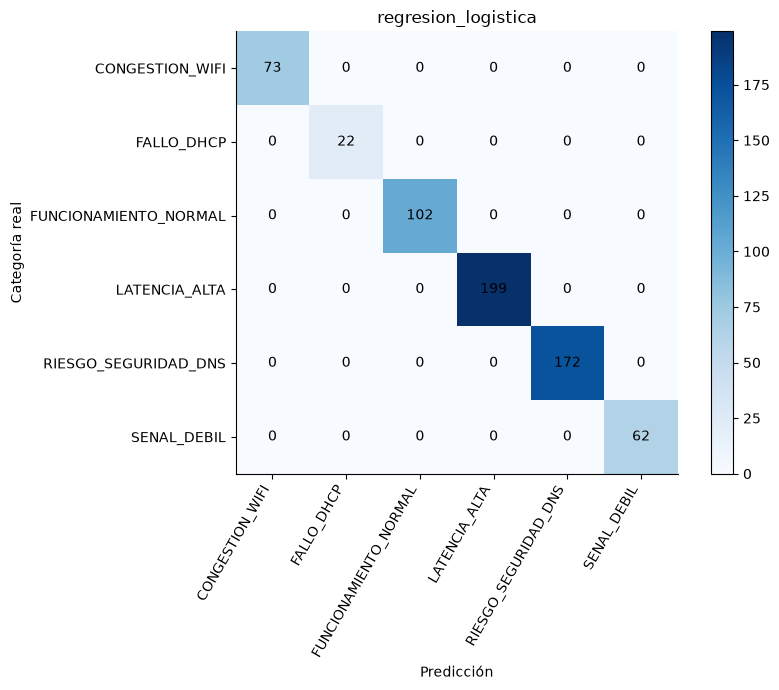

Errores registrados: 0
naive_bayes


,precision,recall,f1-score,support
CONGESTION_WIFI,1.0,1.0,1.0,73.0
FALLO_DHCP,1.0,1.0,1.0,22.0
FUNCIONAMIENTO_NORMAL,1.0,1.0,1.0,102.0
LATENCIA_ALTA,1.0,1.0,1.0,199.0
RIESGO_SEGURIDAD_DNS,1.0,1.0,1.0,172.0
SENAL_DEBIL,1.0,1.0,1.0,62.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,630.0
weighted avg,1.0,1.0,1.0,630.0


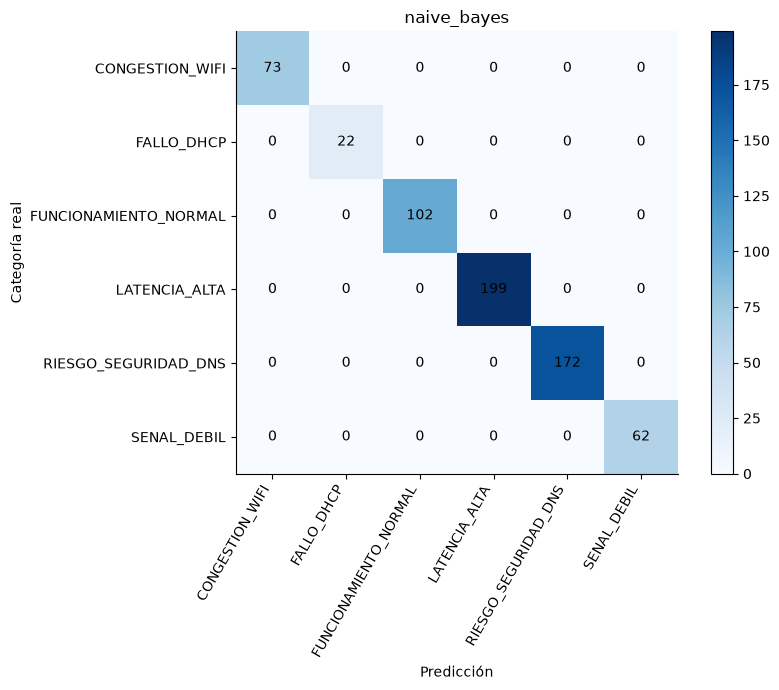

Errores registrados: 0


In [8]:
for nombre, resultado in metricas["modelos"].items():
    evaluacion = resultado["prueba"]
    print(nombre)
    display(pd.DataFrame(evaluacion["reporte"]).T)
    matriz = evaluacion["matriz_confusion"]
    categorias = evaluacion["categorias"]
    figura, eje = plt.subplots(figsize=(9, 7))
    imagen = eje.imshow(matriz, cmap="Blues")
    eje.set_xticks(range(len(categorias)), categorias, rotation=60, ha="right")
    eje.set_yticks(range(len(categorias)), categorias)
    eje.set(xlabel="Predicción", ylabel="Categoría real", title=nombre)
    for i, fila in enumerate(matriz):
        for j, valor in enumerate(fila):
            eje.text(j, i, str(valor), ha="center", va="center")
    figura.colorbar(imagen, ax=eje)
    plt.tight_layout()
    plt.show()
    print("Errores registrados:", len(evaluacion["errores"]))
    if evaluacion["errores"]:
        display(pd.DataFrame(evaluacion["errores"]).head(10))

## 8. Interpretación y pendientes

- Ambos modelos obtuvieron F1 macro 1.0 en la evaluación sintética guardada. No hay errores en esa prueba que analizar; no se deben inventar errores ni afirmar que nunca fallarán.
- La coincidencia de plantillas entre entrenamiento y prueba explica por qué esta evaluación puede resultar fácil. Hay seis categorías y solo dos redacciones base por categoría.
- Se eligió regresión logística con stemming, unigramas, C=0.1 y pesos balanceados por la regla de desempate. El empate no demuestra que stemming sea superior a lematización ni unigramas a bigramas.
- Deben recolectarse descripciones independientes, con etiquetas revisadas por una persona con conocimientos de redes. Las métricas de ese conjunto permitirán analizar errores reales de clasificación.
- Posibles dificultades que todavía no están evaluadas: descripciones ambiguas, varias fallas en un reporte, abreviaturas, errores ortográficos y síntomas insuficientes. Son hipótesis, no resultados medidos.
- El CSV contiene un estado normal además de fallas; el clasificador no verifica físicamente el dispositivo ni asigna prioridad por sí mismo.
- La traducción y el código tuvieron asistencia de IA. El equipo debe revisar las etiquetas y traducciones, confirmar el uso de datos sintéticos con el docente y explicar las decisiones.

Este notebook aporta análisis exploratorio y tablas de experimentos; no sustituye el informe técnico, la evaluación independiente ni la demostración completa de la aplicación.

## 9. Evaluación adicional: casos nuevos y análisis de errores

Se prepararon **18 escenarios sintéticos nuevos** con asistencia de IA, tres por categoría, antes de ejecutar sus predicciones. No se reentrenó ni seleccionó el modelo con ellos. Sus etiquetas son provisionales y deben ser revisadas por el grupo con conocimientos de redes. No son incidentes reales ni una muestra representativa; sirven como prueba de desafío.

Se confirmó que no coincidan con los textos normalizados del CSV de entrenamiento. Para repetir: `python -m src.models.analizar_errores`. Se conservan los casos y las huellas del modelo y CSV. El resultado adicional no reemplaza las métricas del conjunto de prueba original.

In [9]:
revision = json.loads((raiz / "artifacts/analisis_errores.json").read_text(encoding="utf-8"))
assert hashlib.sha256((raiz / "artifacts/pipeline.joblib").read_bytes()).hexdigest() == revision["modelo_sha256"]
assert hashlib.sha256((raiz / "data/evaluacion/casos_revision.csv").read_bytes()).hexdigest() == revision["casos_sha256"]
casos = pd.DataFrame(revision["casos"])
print(f"Aciertos: {casos['acierto'].sum()}/{len(casos)} ({revision['accuracy']:.1%})")
print("F1 macro:", round(revision["reporte"]["macro avg"]["f1-score"], 3))
display(pd.DataFrame(revision["reporte"]).T)
with pd.option_context("display.max_colwidth", None):
    display(casos.loc[~casos["acierto"], ["texto", "categoria", "prediccion", "probabilidad", "justificacion_etiqueta"]])

Aciertos: 10/18 (55.6%)


F1 macro: 0.522


,precision,recall,f1-score,support
CONGESTION_WIFI,1.000000,0.666667,0.800000,3.000000
FALLO_DHCP,0.500000,1.000000,0.666667,3.000000
FUNCIONAMIENTO_NORMAL,0.000000,0.000000,0.000000,3.000000
LATENCIA_ALTA,0.000000,0.000000,0.000000,3.000000
RIESGO_SEGURIDAD_DNS,1.000000,1.000000,1.000000,3.000000
SENAL_DEBIL,0.666667,0.666667,0.666667,3.000000
accuracy,0.555556,0.555556,0.555556,0.555556
macro avg,0.527778,0.555556,0.522222,18.000000
weighted avg,0.527778,0.555556,0.522222,18.000000


,texto,categoria,prediccion,probabilidad,justificacion_etiqueta
0,"La conexión funciona junto al router, pero se corta al entrar al dormitorio. Acercar el equipo restaura el servicio.",SENAL_DEBIL,FUNCIONAMIENTO_NORMAL,0.314952,La dependencia de la distancia y la recuperación al acercarse apuntan a cobertura insuficiente.
6,"El cable está conectado y la recepción es excelente, pero cada ping tarda medio segundo. No se detecta saturación del canal inalámbrico.",LATENCIA_ALTA,FALLO_DHCP,0.247152,Hay demora de respuesta explícita y se descarta congestión Wi-Fi en el escenario.
7,"La videollamada responde con retraso: se midieron 700 milisegundos de ida y vuelta en el enlace cableado, sin problemas de asignación IP.",LATENCIA_ALTA,FALLO_DHCP,0.266962,La medición de ida y vuelta elevada en cableado señala latencia.
8,"Los paquetes llegan sin pérdidas, pero el eco del servidor tarda 900 ms. La transferencia conserva su velocidad habitual.",LATENCIA_ALTA,FUNCIONAMIENTO_NORMAL,0.423647,La demora medida existe aun sin pérdida de paquetes ni caída de transferencia.
10,La red se vuelve lenta cuando se conectan cuarenta clientes al punto de acceso. La señal es buena y el uso del canal llega al 98%.,CONGESTION_WIFI,SENAL_DEBIL,0.395946,La alta ocupación del medio con buena señal apunta a congestión Wi-Fi.
15,"Se completaron las pruebas de conectividad: la IP se obtuvo correctamente, los nombres resuelven y las aplicaciones responden dentro del tiempo esperado.",FUNCIONAMIENTO_NORMAL,LATENCIA_ALTA,0.349871,Las comprobaciones informadas no muestran anomalías.
16,"El monitoreo no detecta incidentes: todas las interfaces están activas, no hay paquetes perdidos y el usuario confirma que puede trabajar.",FUNCIONAMIENTO_NORMAL,FALLO_DHCP,0.232850,Se informa ausencia de incidentes y funcionamiento comprobado.
17,No hay señal débil ni congestión; la latencia se mantiene en 12 ms. DHCP y DNS respondieron correctamente durante toda la revisión.,FUNCIONAMIENTO_NORMAL,LATENCIA_ALTA,0.212199,Es un control de negación: menciona fallas para descartarlas y aporta mediciones normales.


### Interpretación de los ocho errores observados

Las siguientes explicaciones son **hipótesis compatibles con el vocabulario y diseño del modelo**, no una demostración causal de sus pesos:

1. **Señal débil → normal:** el reporte describe dependencia de distancia sin usar la fórmula «RSSI débil»; aparecen palabras positivas como «funciona» y «restaura».
2. **Latencia → DHCP (ping):** «medio segundo» y «ping» expresan demora con vocabulario distinto al entrenamiento. La negación de saturación tampoco resuelve la causa.
3. **Latencia → DHCP (videollamada):** «milisegundos de ida y vuelta» y la referencia a asignación IP pueden desplazar la clasificación hacia DHCP aunque se diga «sin problemas».
4. **Latencia → normal (eco):** «eco del servidor tarda 900 ms» expresa latencia sin nombrarla; «sin pérdidas» y «velocidad habitual» son señales de normalidad que no descartan demora.
5. **Congestión → señal débil:** el reporte indica alta ocupación con buena señal; el modelo puede depender de palabras como «señal» y no interpretar bien el valor numérico 98%.
6. **Normal → latencia (pruebas):** describe resultados normales con una redacción distinta; el clasificador no deduce necesariamente que «dentro del tiempo esperado» significa respuesta normal.
7. **Normal → DHCP (monitoreo):** ausencia de incidentes y pérdida de paquetes no sigue las plantillas de normalidad aprendidas. Requiere más variedad de negativos y revisión de rasgos.
8. **Normal → latencia (negación):** menciona señal débil, congestión y latencia para descartarlas. La configuración ganadora usa unigramas, que no representan explícitamente la relación entre una negación y el síntoma.

**Resultado:** 10/18 aciertos (55,6%) en este pequeño conjunto construido, frente al 100% del test con plantillas. Las muestras no son comparables estadísticamente; la diferencia evidencia una limitación que merece investigación, no una estimación de rendimiento real.

**Mejoras propuestas:** textos más variados y etiquetados por técnicos, mediciones como variables numéricas si se amplía el alcance, ejemplos de negación y revisión de representaciones con contexto. No se aplicaron para evitar ajustar sobre estos casos. Si se usan para mejorar el modelo, pasan a ser desarrollo y se necesita otro conjunto independiente de evaluación.